In [1]:
import pandas as pd
df = pd.read_csv('../../data/Vessels_PositionReport_5min_25Dec2024_25Jan2025.csv')

In [2]:
df.columns

Index(['DATE TIME (UTC)', 'MMSI', 'LATITUDE', 'LONGITUDE', 'COURSE', 'SPEED',
       'HEADING', 'NAVSTAT', 'IMO', 'NAME', 'CALLSIGN', 'AISTYPE', 'A', 'B',
       'C', 'D', 'DRAUGHT', 'DESTINATION', 'ETA'],
      dtype='object')

In [3]:
df['AISTYPE'].unique()

array([71, 79, 70, 73, 78,  0, 72, 74, 89])

In [4]:
# https://api.vtexplorer.com/docs/ref-aistypes.html
ais_type_mapping = {
    70: ('Cargo', None),
    71: ('Cargo', 'Hazard A'),
    72: ('Cargo', 'Hazard B'),
    73: ('Cargo', 'Hazard C'),
    74: ('Cargo', 'Hazard D'),
    78: ('Cargo', 'Reserved'),
    79: ('Cargo', None),
    89: ('Tanker', None),
    0:  (None, None)
}

df['SHIP TYPE'] = df['AISTYPE']\
    .apply(lambda ais_type_key: ais_type_mapping[ais_type_key][0])
df['CARGO TYPE'] = df['AISTYPE']\
    .apply(lambda ais_type_key: ais_type_mapping[ais_type_key][1])

In [5]:
df['SHIP TYPE'].value_counts()

SHIP TYPE
Cargo     103576
Tanker         1
Name: count, dtype: int64

In [6]:
df['CARGO TYPE'].value_counts(dropna=False)

CARGO TYPE
None        76154
Hazard A    21102
Hazard C     3940
Hazard D     1671
Hazard B     1029
Reserved      155
Name: count, dtype: int64

In [7]:
df = df[df['SPEED'] < 25]
df = df[df['COURSE'] < 360.0]
df = df[df['HEADING'] < 360.0]

In [8]:
df['NAVSTAT'].value_counts()

NAVSTAT
0    65778
5    33476
1     2936
8      109
2       21
Name: count, dtype: int64

In [9]:
nav_stat_mapping = {
    0: 'Under way using engine',
    1: 'Under way using engine',
    2: 'Not under command',
    5: 'Moored',
    8: 'Under way sailing'
}

df['NAVIGATION STATUS'] = df['NAVSTAT'].apply(lambda nav_stat: nav_stat_mapping[nav_stat])

SPEED    Axes(0.125,0.11;0.775x0.77)
dtype: object

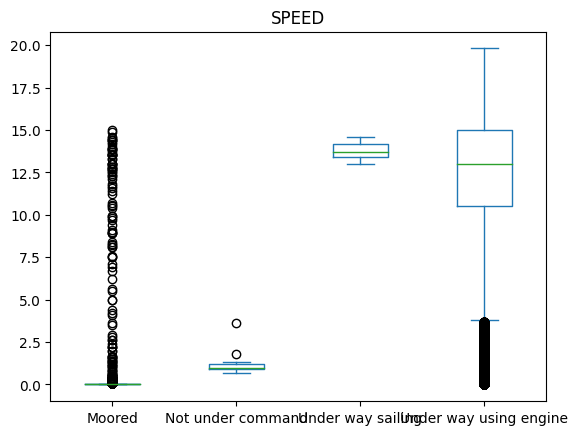

In [10]:
df.plot.box('NAVIGATION STATUS', column='SPEED')

In [11]:
df.shape[0]

102320

SPEED    Axes(0.125,0.11;0.775x0.77)
dtype: object

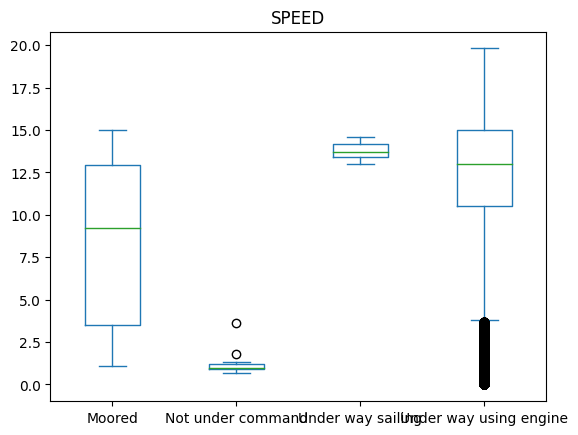

In [12]:
df[
    ((df['NAVIGATION STATUS'] == 'Moored') &
    (df['SPEED'] > 1)) |
    (df['NAVIGATION STATUS'] != 'Moored')
].plot.box(column='SPEED', by='NAVIGATION STATUS')

In [13]:
df['DAY'] = pd.to_datetime(df['DATE TIME (UTC)']).dt.normalize()

In [14]:
df[
    ((df['NAVIGATION STATUS'] == 'Moored') &
    (df['SPEED'] > 1))
][['MMSI', 'DAY']].drop_duplicates()\
    .value_counts()

MMSI       DAY       
228467900  2024-12-28    1
           2024-12-29    1
305978000  2025-01-15    1
305741000  2025-01-18    1
305643000  2025-01-22    1
256336000  2025-01-24    1
           2025-01-23    1
           2025-01-03    1
           2025-01-02    1
           2024-12-30    1
255806525  2025-01-20    1
255806513  2025-01-24    1
           2025-01-22    1
           2025-01-08    1
255805956  2025-01-23    1
           2025-01-22    1
255805577  2025-01-07    1
255804760  2025-01-05    1
245258000  2025-01-23    1
232046826  2025-01-07    1
228468700  2025-01-08    1
374855000  2025-01-08    1
Name: count, dtype: int64

In [15]:
from datetime import datetime

df[
    (df['MMSI'] == 228467900) & 
    (df['DAY'].apply(lambda x: x in [datetime(2024,12,28), datetime(2024,12,29), datetime(2024,12,30)])) &
    (df['NAVIGATION STATUS'] == 'Moored') &
    (df['SPEED'] > 1)
]\
    .sort_values('DATE TIME (UTC)')\
    [['LATITUDE', 'LONGITUDE', 'SPEED']]

,LATITUDE,LONGITUDE,SPEED
10142,60.21497,25.18874,1.3
13023,59.49332,24.96309,2.6


In [16]:
df['DATE TIME'] = pd.to_datetime(df['DATE TIME (UTC)'])

In [17]:
from datetime import timedelta

In [18]:
import matplotlib.pyplot as plt
import numpy as np

In [19]:
df['LATITUDE'].min(), df['LATITUDE'].max(), df['LONGITUDE'].min(), df['LONGITUDE'].max()

(57.00014, 60.49967, 18.50007, 25.49999)

In [20]:
df['DATE TIME'].min()

Timestamp('2024-12-25 00:00:03')

In [21]:
df_weather = pd.read_csv('../../data/weather_df_eagles_vezhen.csv')
df_weather.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 33000 entries, 0 to 32999
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Unnamed: 0        33000 non-null  int64  
 1   currentDirection  33000 non-null  float64
 2   currentSpeed      33000 non-null  float64
 3   gust              33000 non-null  float64
 4   swellDirection    33000 non-null  float64
 5   swellHeight       33000 non-null  float64
 6   time              33000 non-null  object 
 7   waveDirection     33000 non-null  float64
 8   waveHeight        33000 non-null  float64
 9   windDirection     33000 non-null  float64
 10  windSpeed         33000 non-null  float64
 11  Longitude         33000 non-null  float64
 12  Latitude          33000 non-null  float64
dtypes: float64(11), int64(1), object(1)
memory usage: 3.3+ MB


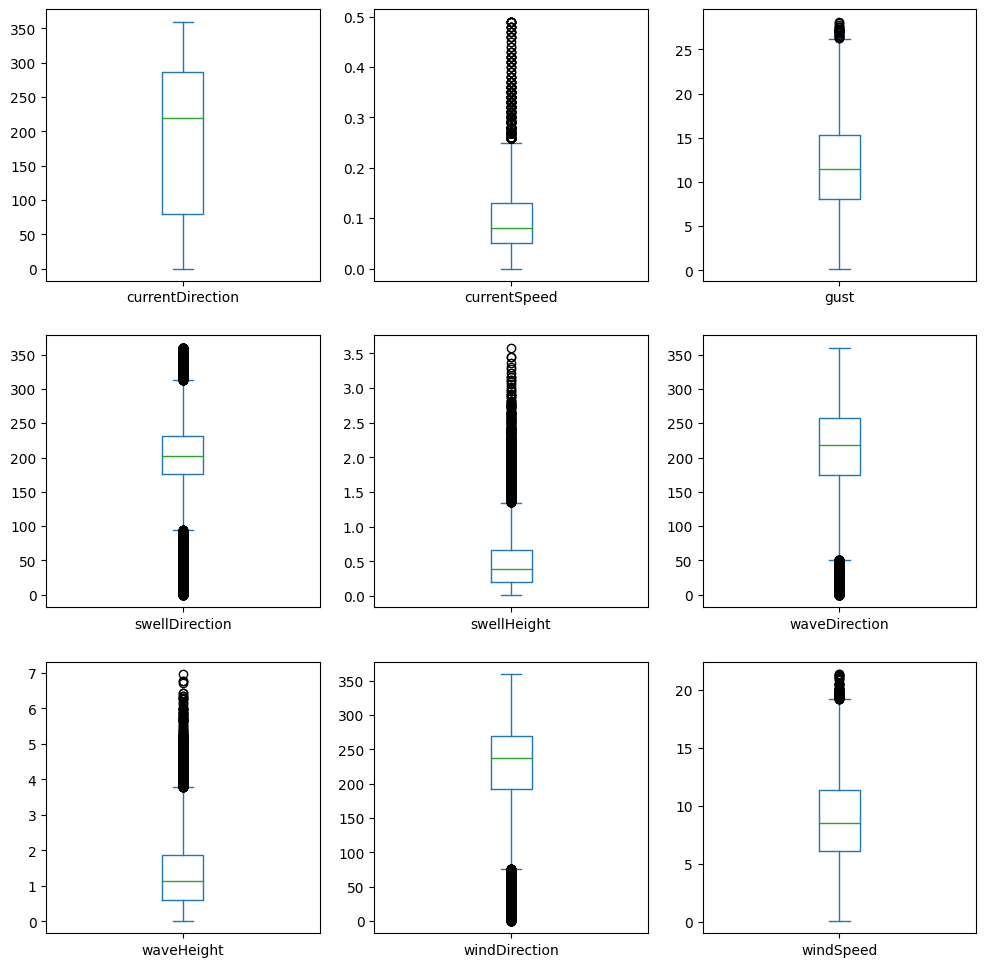

In [22]:
WEATHER_VARS = [
    "currentDirection", 
    "currentSpeed", 
    "gust",
    "swellDirection",
    "swellHeight",
    "waveDirection",
    "waveHeight",
    "windDirection",
    "windSpeed",
]

fig,axs = plt.subplots(nrows=3, ncols=3, figsize=(12,12))
for col, ax in zip(WEATHER_VARS, axs.ravel()):
    df_weather[col]\
        .plot.box(ax=ax)

In [27]:
df['DATE TIME (UTC)'] = pd.to_datetime( df['DATE TIME (UTC)'] )
df['day'] = df['DATE TIME (UTC)'].dt.date

def add_course_delta(group):
    group['cog_delta_abs'] = np.abs( (group['COURSE'].diff(1) + 180 ) % 360 - 180 )
    group['dif'] = (group['COURSE'] - group['HEADING'] + 180 ) % 360 - 180
    group['delta_dif_abs'] = group['dif'].diff(1).abs()
    group['dif_abs'] = group['dif'].abs()
    return group.drop(columns=['MMSI', 'day'])

df_ = df.sort_values('DATE TIME (UTC)')\
    .groupby(['MMSI', 'day'])\
    .apply(add_course_delta)\
    .reset_index()\
    .drop(columns='level_2')

In [28]:
import seaborn as sns

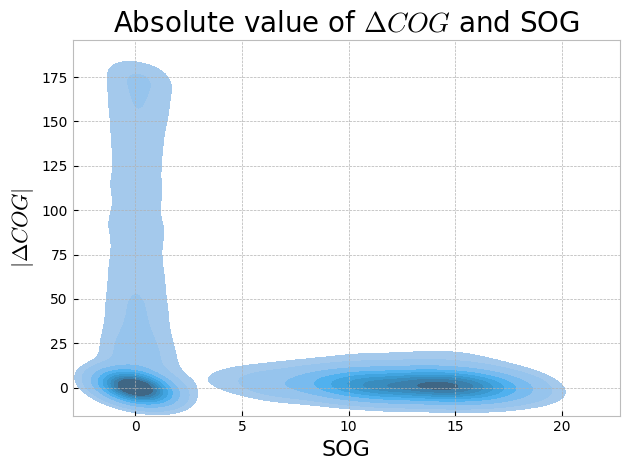

In [29]:
plt.style.use('bmh')
plt.rcParams['axes.facecolor'] = 'white'
sns.kdeplot(data=df_, x='SPEED', y='cog_delta_abs', fill=True)
plt.ylabel(r'$|\Delta COG|$', size=16)
plt.xlabel('SOG', size=16)
plt.title(r'Absolute value of $\Delta COG$ and SOG', size=20)
plt.tight_layout()
plt.savefig('delta_cog_speed.png')

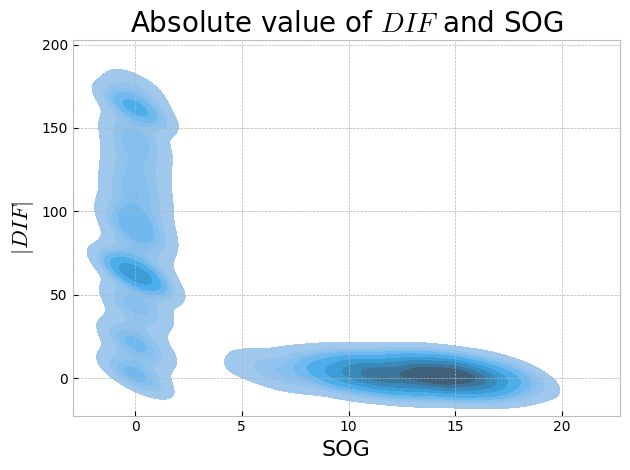

In [31]:
plt.style.use('bmh')
plt.rcParams['axes.facecolor'] = 'white'
sns.kdeplot(data=df_, x='SPEED', y='dif_abs', fill=True)
plt.ylabel(r'$|DIF|$', size=16)
plt.xlabel('SOG', size=16)
plt.title(r'Absolute value of $DIF$ and SOG', size=20)
plt.tight_layout()
plt.savefig('dif_speed.png')

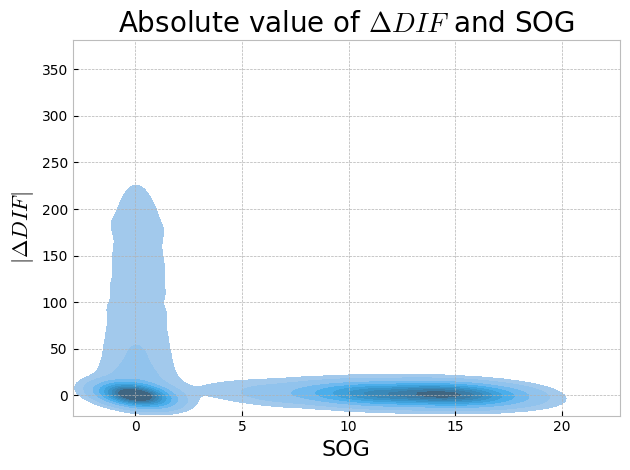

In [33]:
plt.style.use('bmh')
plt.rcParams['axes.facecolor'] = 'white'
sns.kdeplot(data=df_, x='SPEED', y='delta_dif_abs', fill=True)
plt.ylabel(r'$|\Delta DIF|$', size=16)
plt.xlabel('SOG', size=16)
plt.title(r'Absolute value of $\Delta DIF$ and SOG', size=20)
plt.tight_layout()
plt.savefig('delta_dif_speed.png')